# Dataset 2: Cyberattacks
This dataset describes cyber attacks.
Each row = one packet session.
| Column | Description |
|--------|-------------|
| `packet_session_id` | Unique ID assigned to each network session |
| `protocol` | Networking Protocol types (TCP, UDP, ICMP) |
| `device_type` | Type of device involved in the session |
| `vpn_status` | Whether or not the session was routed through a VPN |
| `region` | Geographic region where the session originated |
| `login_attempts` | Total number of login attempts made during the session |
| `failed_logins` | Number of those login attempts that failed |
| `bytes_sent` | Total bytes sent from the device during the session |
| `bytes_received` | Total bytes received by the device during the session |
| `packet_rate` | Number of packets transmitted per second |
| `connection_count` | Number of unique connections made during the session |
| `tcp_flags` | Control flags in the TCP header |
| `port_number` | The destination port of the connection |
| `session_retries` | Number of times the session attempted to reconnect/retry |
| `signal_strength` | Wireless signal strength |
| `privilege_level` | Access privilege level of the user in the session |
| `anomaly_score` | Risk score of session |
| `avg_packet_size` | **PREDICTION TARGET** mean size (in bytes) of individual packets within the session |
| `attack_category` | **CLASSIFICATION TARGET** whether it was a brute force attack or benign |

---

## 1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    mean_squared_error, mean_absolute_error, r2_score
)

print("All libraries loaded successfully!")

All libraries loaded successfully!


## 2. Load the Dataset


In [ ]:
df = pd.read_csv("Dataset2_odd_students.csv")
df_orig = df.copy()

# Print the shape and preview the first 10 rows
print(f"Dataset : {df.shape[0]:,} rows × {df.shape[1]} columns")

Dataset : 6,000 rows × 19 columns


## 3. Exploratory Data Analysis (EDA)

First look at data:

In [ ]:
df.info() # column names, data types, non-null counts

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 19 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   packet_session_id  6000 non-null   object 
 1   protocol           5580 non-null   object 
 2   device_type        6000 non-null   object 
 3   vpn_status         6000 non-null   object 
 4   region             6000 non-null   object 
 5   login_attempts     6000 non-null   int64  
 6   failed_logins      6000 non-null   int64  
 7   bytes_sent         6000 non-null   float64
 8   bytes_received     5580 non-null   float64
 9   packet_rate        6000 non-null   float64
 10  connection_count   6000 non-null   int64  
 11  tcp_flags          6000 non-null   object 
 12  port_number        6000 non-null   int64  
 13  session_retries    6000 non-null   int64  
 14  signal_strength    5580 non-null   float64
 15  privilege_level    6000 non-null   object 
 16  anomaly_score      6000 

In [ ]:
df.describe() # stats for numeric columns

,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,port_number,session_retries,signal_strength,anomaly_score,avg_packet_size
count,6000.000000,6000.00000,6000.000000,5580.000000,6000.000000,6000.000000,6000.000000,6000.000000,5580.000000,6000.000000,6000.000000
mean,1.986167,1.01300,5244.930668,6030.812597,125.406064,5.007500,464.325667,0.990000,-60.001938,0.288818,291.962610
std,1.403913,1.00565,3148.811236,2024.969118,66.673500,2.231802,1022.536272,0.987453,9.956151,0.161198,23.270255
min,0.000000,0.00000,100.000000,100.000000,10.000000,0.000000,21.000000,0.000000,-96.498666,0.004041,198.964322
25%,1.000000,0.00000,3985.123437,4698.079531,99.429233,3.000000,25.000000,0.000000,-66.730775,0.164258,276.480544
50%,2.000000,1.00000,4971.300665,6036.927406,120.364024,5.000000,80.000000,1.000000,-59.985307,0.267198,291.736995
75%,3.000000,2.00000,6017.944743,7403.422659,140.340118,6.000000,143.000000,2.000000,-53.391908,0.395506,307.606272
max,8.000000,6.00000,53602.250239,14261.024735,1068.619903,16.000000,3389.000000,6.000000,-25.848112,0.851668,375.361722


In [ ]:
df.describe(include="all") # includes categorical columns too

,packet_session_id,protocol,device_type,vpn_status,region,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,tcp_flags,port_number,session_retries,signal_strength,privilege_level,anomaly_score,avg_packet_size,attack_category
count,6000,5580,6000,6000,6000,6000.000000,6000.00000,6000.000000,5580.000000,6000.000000,6000.000000,6000,6000.000000,6000.000000,5580.000000,6000,6000.000000,6000.000000,6000
unique,6000,5,4,2,4,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,NaN,NaN,3,NaN,NaN,2
top,P005983,TCP,Workstation,Off,APAC,NaN,NaN,NaN,NaN,NaN,NaN,SYN-ACK,NaN,NaN,NaN,user,NaN,NaN,Benign
freq,1,2443,1537,4197,1523,NaN,NaN,NaN,NaN,NaN,NaN,1531,NaN,NaN,NaN,4277,NaN,NaN,4161
mean,NaN,NaN,NaN,NaN,NaN,1.986167,1.01300,5244.930668,6030.812597,125.406064,5.007500,NaN,464.325667,0.990000,-60.001938,NaN,0.288818,291.962610,NaN
std,NaN,NaN,NaN,NaN,NaN,1.403913,1.00565,3148.811236,2024.969118,66.673500,2.231802,NaN,1022.536272,0.987453,9.956151,NaN,0.161198,23.270255,NaN
min,NaN,NaN,NaN,NaN,NaN,0.000000,0.00000,100.000000,100.000000,10.000000,0.000000,NaN,21.000000,0.000000,-96.498666,NaN,0.004041,198.964322,NaN
25%,NaN,NaN,NaN,NaN,NaN,1.000000,0.00000,3985.123437,4698.079531,99.429233,3.000000,NaN,25.000000,0.000000,-66.730775,NaN,0.164258,276.480544,NaN
50%,NaN,NaN,NaN,NaN,NaN,2.000000,1.00000,4971.300665,6036.927406,120.364024,5.000000,NaN,80.000000,1.000000,-59.985307,NaN,0.267198,291.736995,NaN
75%,NaN,NaN,NaN,NaN,NaN,3.000000,2.00000,6017.944743,7403.422659,140.340118,6.000000,NaN,143.000000,2.000000,-53.391908,NaN,0.395506,307.606272,NaN


In [ ]:
df.head(10) # first 10 rows

,packet_session_id,protocol,device_type,vpn_status,region,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,tcp_flags,port_number,session_retries,signal_strength,privilege_level,anomaly_score,avg_packet_size,attack_category
0,P000000,TCP,Workstation,On,APAC,0,6,3735.701997,7083.530344,184.514770,7,FIN,3389,0,-71.345111,user,0.117355,332.602010,Benign
1,P000001,TCP,Workstation,Off,EU,1,2,6140.866808,4382.336675,155.062604,5,ACK,110,1,-44.351883,user,0.238888,314.553416,Benign
2,P000002,TCP,Workstation,Off,US,3,0,4714.244672,6979.428832,125.959250,4,FIN,80,0,-64.475005,user,0.123961,266.942545,Benign
3,P000003,UDP,Server,Off,APAC,2,0,2987.854450,2715.307765,88.444309,3,FIN,110,1,-48.033202,guest,0.462781,259.362639,BruteForce
4,P000004,UDP,IoT,Off,US,1,5,5021.324823,4858.666310,153.385483,2,SYN-ACK,110,2,-65.320352,user,0.185527,293.294721,BruteForce
5,P000005,TCP,Workstation,On,EU,3,1,5611.170345,7618.088822,115.158658,3,SYN,110,0,-68.288010,admin,0.570801,284.647177,BruteForce
6,P000006,tcp,Workstation,Off,EU,6,2,3140.607112,5539.065998,145.283235,5,SYN,21,1,-64.918360,guest,0.344138,305.526912,Benign
7,P000007,NaN,Mobile,On,APAC,4,0,5369.040024,7248.335284,127.831649,7,SYN,110,0,-57.737418,user,0.135030,318.689917,Benign
8,P000008,ICMP,IoT,Off,US,3,1,33385.813113,9726.207835,138.591434,10,SYN-ACK,53,3,-59.282052,user,0.434628,346.286492,Benign
9,P000009,UDP,Workstation,Off,EU,2,2,1486.056410,5089.932042,104.080559,5,ACK,21,3,-65.828516,user,0.552794,216.432037,Benign


In [ ]:
df.tail(10) # last 10 rows

,packet_session_id,protocol,device_type,vpn_status,region,login_attempts,failed_logins,bytes_sent,bytes_received,packet_rate,connection_count,tcp_flags,port_number,session_retries,signal_strength,privilege_level,anomaly_score,avg_packet_size,attack_category
5990,P005990,TCP,Server,Off,US,4,3,2728.011146,7618.218438,140.230738,9,ACK,53,0,-51.668601,user,0.315074,288.556347,Benign
5991,P005991,TCP,Mobile,Off,EU,1,0,4979.643471,7338.952272,162.725208,4,FIN,443,0,-62.417654,user,0.332337,310.475476,Benign
5992,P005992,ICMP,Workstation,On,ME,3,3,7632.430255,4245.579002,180.593288,7,ACK,110,1,-61.068660,user,0.681547,331.280557,Benign
5993,P005993,NaN,Workstation,Off,US,5,1,6268.273637,8735.793595,83.719025,3,FIN,143,0,-61.142443,user,0.174984,264.344692,BruteForce
5994,P005994,NaN,Server,Off,US,5,0,4277.420762,8080.471633,141.159805,5,SYN,22,1,-76.734076,user,0.297054,324.540254,Benign
5995,P005995,UDP,Mobile,Off,EU,2,1,5214.959744,7257.458366,140.430482,6,FIN,443,0,-79.173217,user,0.380859,306.974066,Benign
5996,P005996,NaN,Mobile,Off,APAC,2,1,5825.344539,7246.444746,117.600652,6,FIN,3389,1,-71.096695,guest,0.289372,287.202104,BruteForce
5997,P005997,UDP,Server,Off,EU,3,4,5373.420838,5756.076385,107.200381,5,SYN,443,2,-49.027112,admin,0.403434,267.478179,BruteForce
5998,P005998,TCP,Workstation,Off,APAC,0,0,5919.800840,7891.417131,123.809701,4,SYN,443,2,-68.448930,admin,0.605481,301.348712,Benign
5999,P005999,ICMP,Server,On,EU,2,1,3665.162627,10088.742511,106.540093,4,ACK,143,2,-61.599034,user,0.473425,278.916439,Benign


In [ ]:
print(df.dtypes) # data type of each column

packet_session_id     object
protocol              object
device_type           object
vpn_status            object
region                object
login_attempts         int64
failed_logins          int64
bytes_sent           float64
bytes_received       float64
packet_rate          float64
connection_count       int64
tcp_flags             object
port_number            int64
session_retries        int64
signal_strength      float64
privilege_level       object
anomaly_score        float64
avg_packet_size      float64
attack_category       object
dtype: object


In [ ]:
dupes = df.duplicated().sum()
print(f"Duplicate rows: {dupes}")

Duplicate rows: 0


checking for missing or invalid values:

In [ ]:
# Count of missing values per column
print(df.isnull().sum())

packet_session_id      0
protocol             420
device_type            0
vpn_status             0
region                 0
login_attempts         0
failed_logins          0
bytes_sent             0
bytes_received       420
packet_rate            0
connection_count       0
tcp_flags              0
port_number            0
session_retries        0
signal_strength      420
privilege_level        0
anomaly_score          0
avg_packet_size        0
attack_category        0
dtype: int64


In [ ]:
# Percentage missing — use this to make decisions
print((df.isnull().sum() / len(df)) * 100)

packet_session_id    0.0
protocol             7.0
device_type          0.0
vpn_status           0.0
region               0.0
login_attempts       0.0
failed_logins        0.0
bytes_sent           0.0
bytes_received       7.0
packet_rate          0.0
connection_count     0.0
tcp_flags            0.0
port_number          0.0
session_retries      0.0
signal_strength      7.0
privilege_level      0.0
anomaly_score        0.0
avg_packet_size      0.0
attack_category      0.0
dtype: float64


In [ ]:
# Show ONLY columns that have missing values
missing = df.isnull().sum()
print(missing[missing > 0])

protocol           420
bytes_received     420
signal_strength    420
dtype: int64


In [ ]:
print("--- Classification Target: attack_category ---")
print(df['attack_category'].value_counts())
print("\n")

--- Classification Target: attack_category ---
attack_category
Benign        4161
BruteForce    1839
Name: count, dtype: int64




In [ ]:
print("--- Regression Target: avg_packet_size ---")
print(df['avg_packet_size'].describe().round(2))

--- Regression Target: avg_packet_size ---
count    6000.00
mean      291.96
std        23.27
min       198.96
25%       276.48
50%       291.74
75%       307.61
max       375.36
Name: avg_packet_size, dtype: float64


In [ ]:
for col in df.select_dtypes('object').columns:
  print(f'\n-----------------')
  print(df[col].value_counts())
  print(f"Unique values: {df[col].nunique()}")


-----------------
packet_session_id
P005983    1
P005982    1
P005981    1
P005980    1
P005979    1
          ..
P000004    1
P000003    1
P000002    1
P000001    1
P000000    1
Name: count, Length: 6000, dtype: int64
Unique values: 6000

-----------------
protocol
TCP     2443
UDP     1435
ICMP     595
tcp      559
udp      548
Name: count, dtype: int64
Unique values: 5

-----------------
device_type
Workstation    1537
Mobile         1512
IoT            1497
Server         1454
Name: count, dtype: int64
Unique values: 4

-----------------
vpn_status
Off    4197
On     1803
Name: count, dtype: int64
Unique values: 2

-----------------
region
APAC    1523
ME      1515
EU      1508
US      1454
Name: count, dtype: int64
Unique values: 4

-----------------
tcp_flags
SYN-ACK    1531
ACK        1522
FIN        1481
SYN        1466
Name: count, dtype: int64
Unique values: 4

-----------------
privilege_level
user     4277
admin    1110
guest     613
Name: count, dtype: int64
Unique values

In [ ]:
cat_missing_cols = [col for col in df.select_dtypes(include='object').columns
                    if df[col].isnull().sum() > 0]

In [ ]:
for col in cat_missing_cols:
  print(df[col].value_counts(dropna=False))

protocol
TCP     2443
UDP     1435
ICMP     595
tcp      559
udp      548
NaN      420
Name: count, dtype: int64


will need to merge the lowercase and capitalcases of TCP and UDP later

In [ ]:
numeric_missing_cols = [col for col in df.select_dtypes(include='number').columns
                        if df[col].isnull().sum() > 0]

In [ ]:
print(f"\n{'Column':<15} {'Mean':>10} {'Median':>14}")
for col in numeric_missing_cols:
  mean = df[col].mean()
  median = df[col].median()
  print(f"{col:<15} {mean:>10f} {median:>14f}")


Column                Mean         Median
bytes_received  6030.812597    6036.927406
signal_strength -60.001938     -59.985307


both are symmetric as mean and median are almost equal to each other when looking at the range of valeus in both columns

In [ ]:
print("impossible value checks")
print(f"bytes_sent negatives : {(df['bytes_sent'] < 0).sum()}")
print(f"bytes_received negatives : {(df['bytes_received'] < 0).sum()}")
print(f"packet_rate negatives : {(df['packet_rate'] < 0).sum()}")
print(f"signal_strength positives (always negative in dBm): {(df['signal_strength'] > 0).sum()}")
print(f"anomaly_score outside [0,1]: {((df['anomaly_score'] < 0) | (df['anomaly_score'] > 1)).sum()}")
print(f"failed_logins > login_attempts: {(df['failed_logins'] > df['login_attempts']).sum()}")
print(f"session_retries > connection_count: {(df['session_retries'] > df['connection_count']).sum()}")

impossible value checks
bytes_sent negatives : 0
bytes_received negatives : 0
packet_rate negatives : 0
signal_strength positives (always negative in dBm): 0
anomaly_score outside [0,1]: 0
failed_logins > login_attempts: 1109
session_retries > connection_count: 144


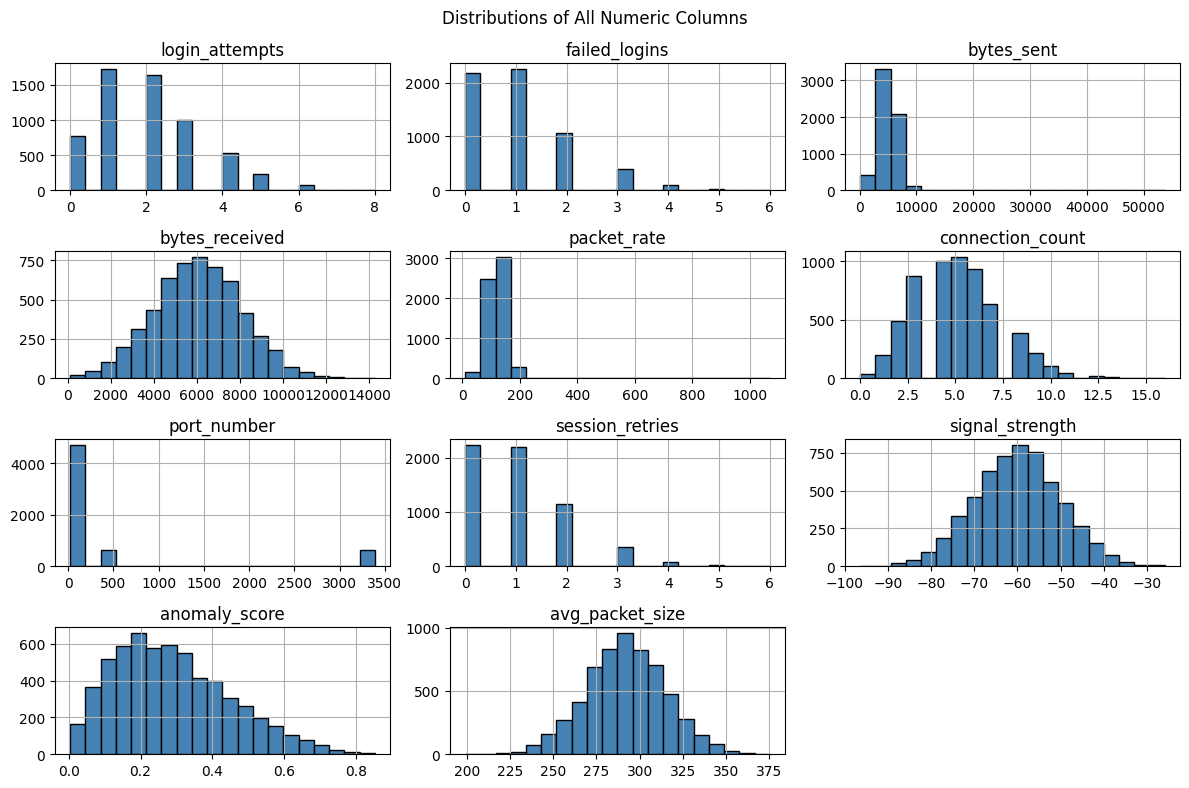

In [ ]:
#Plot 1 - Histograms
df.hist(figsize=(12, 8), bins=20, color='steelblue', edgecolor='black')
plt.suptitle('Distributions of All Numeric Columns')
plt.tight_layout()
plt.show()

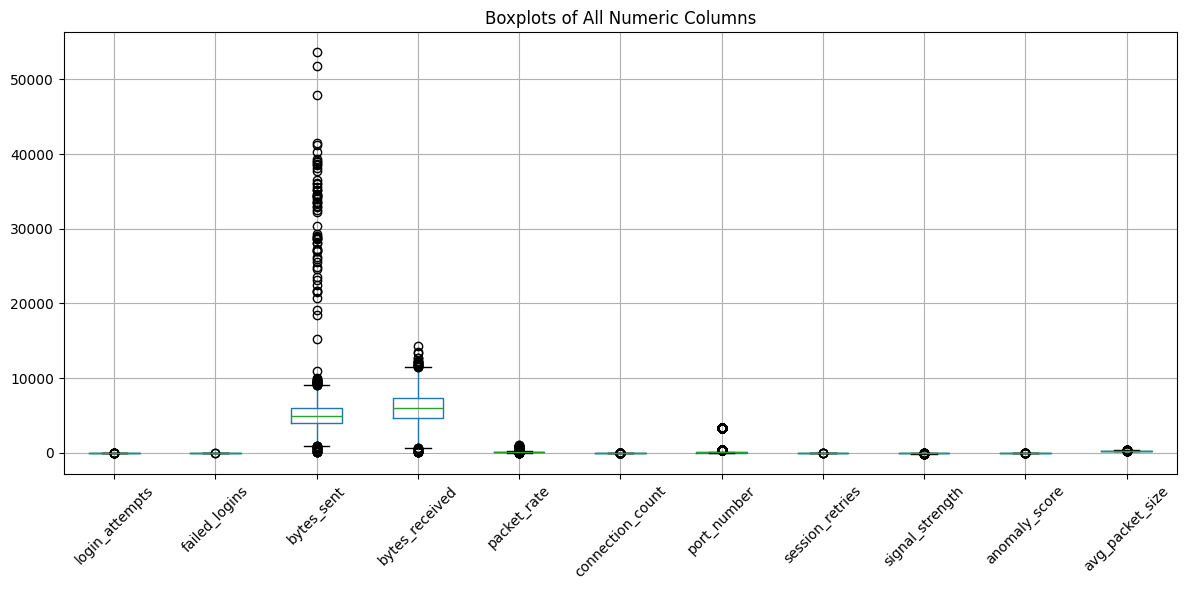

In [ ]:
#Plot 2 - Boxplot:
plt.figure(figsize=(12, 6))
df.select_dtypes(include='number').boxplot()
plt.title('Boxplots of All Numeric Columns')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

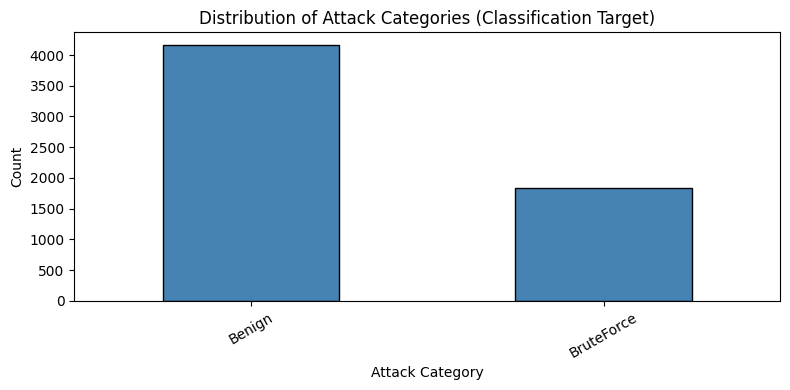

attack_category
Benign        4161
BruteForce    1839
Name: count, dtype: int64


In [ ]:
#Plot 3 - Bar Chart of classificition targett
plt.figure(figsize=(8, 4))
df['attack_category'].value_counts().plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Distribution of Attack Categories (Classification Target)')
plt.xlabel('Attack Category')
plt.ylabel('Count')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
print(df['attack_category'].value_counts())

/tmp/ipykernel_735/1843638122.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='attack_category', y='avg_packet_size', data=df, palette='Set2')


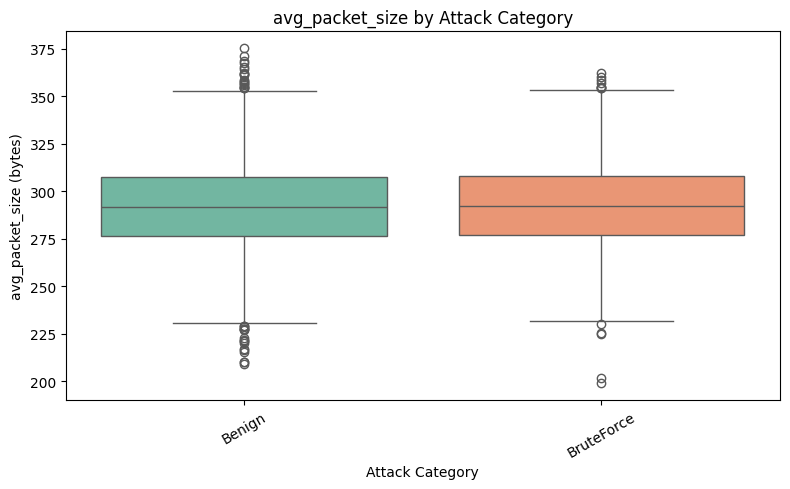

In [ ]:
#Plot 4 - Numeric Feature vs Target
plt.figure(figsize=(8, 5))
sns.boxplot(x='attack_category', y='avg_packet_size', data=df, palette='Set2')
plt.title('avg_packet_size by Attack Category')
plt.xlabel('Attack Category')
plt.ylabel('avg_packet_size (bytes)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

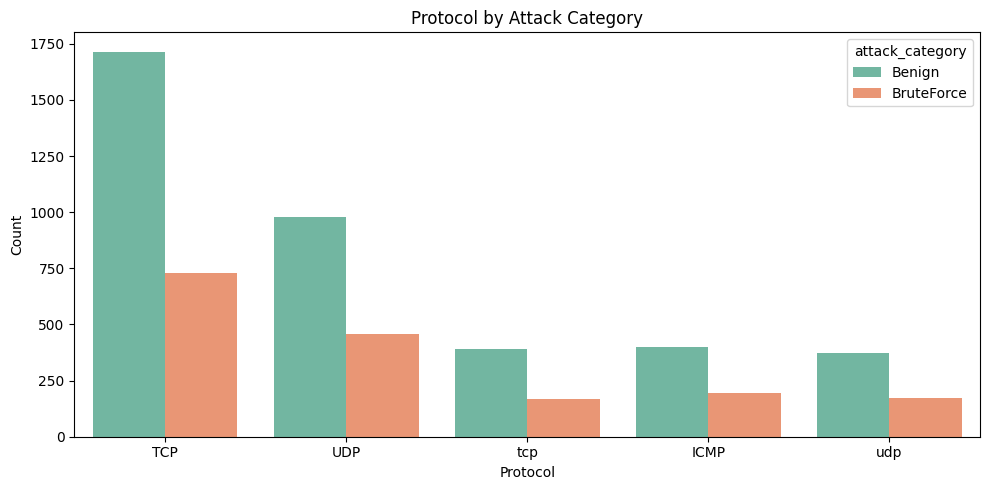

In [ ]:
# Plot 5 - Categorical Feature vs Target
plt.figure(figsize=(10, 5))
sns.countplot(x='protocol', hue='attack_category', data=df, palette='Set2')
plt.title('Protocol by Attack Category')
plt.xlabel('Protocol')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

<Axes: xlabel='bytes_sent', ylabel='bytes_received'>

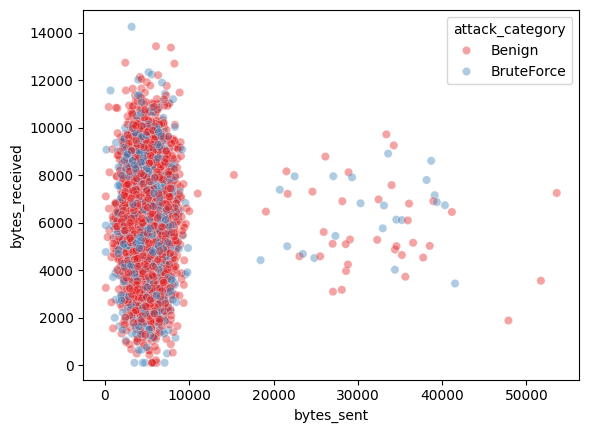

In [ ]:
#Plot 6 - Scatter Plot
sns.scatterplot(x='bytes_sent', y='bytes_received', hue='attack_category',
                data=df, palette='Set1', alpha=0.4)

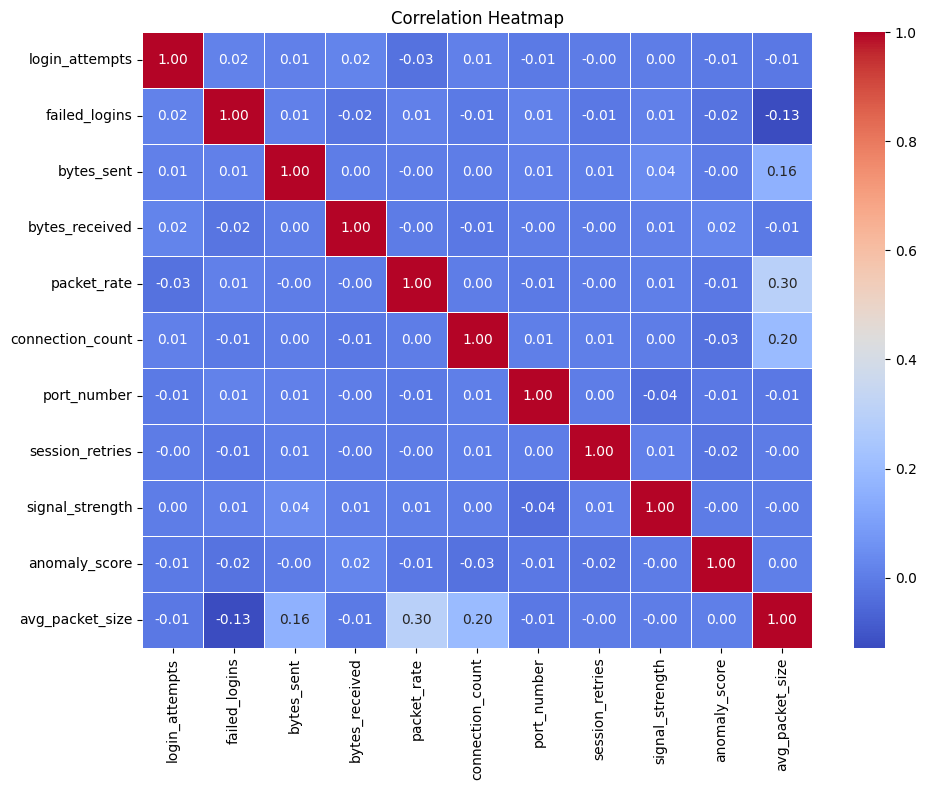


--- Strong Correlations (|r| > 0.7, excluding self) ---
None found.


In [ ]:
#Plot 7 - Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm',
            fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

print("\n--- Strong Correlations (|r| > 0.7, excluding self) ---")
corr = df.corr(numeric_only=True)
strong = [(corr.columns[i], corr.columns[j], round(corr.iloc[i,j],3))
          for i in range(len(corr.columns))
          for j in range(i+1, len(corr.columns))
          if abs(corr.iloc[i,j]) > 0.7]
print(strong if strong else "None found.")

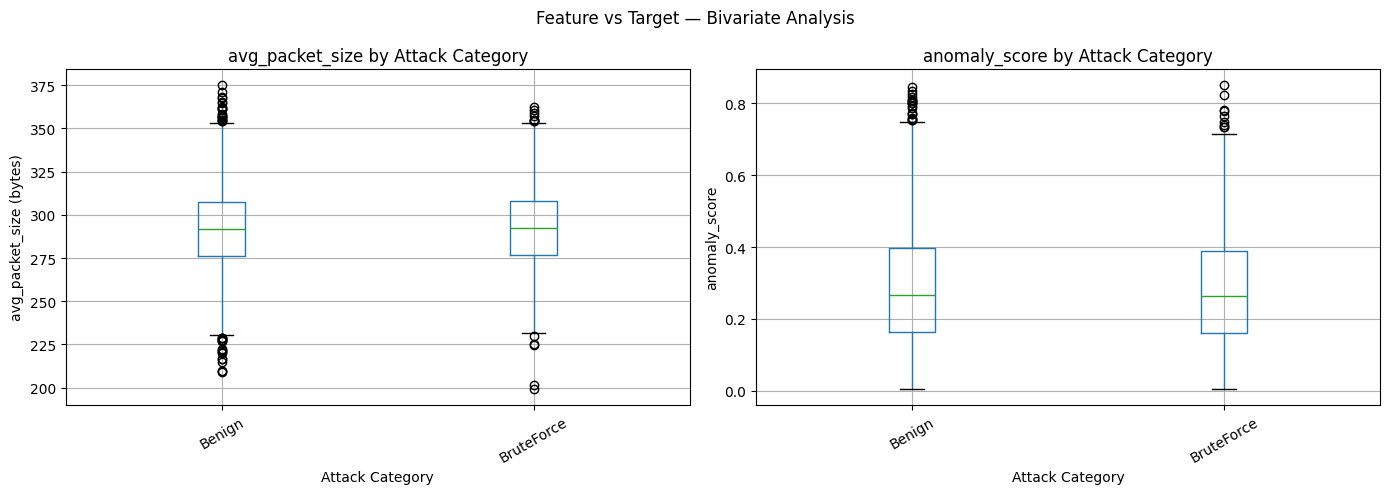

In [ ]:
#Plot 8 - bivariate analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#regression target vs classification target
df.boxplot(column=['avg_packet_size'], by='attack_category', ax=axes[0])
axes[0].set_title('avg_packet_size by Attack Category')
axes[0].set_xlabel('Attack Category')
axes[0].set_ylabel('avg_packet_size (bytes)')
axes[0].tick_params(axis='x', rotation=30)

#strongest numeric predictor vs target
df.boxplot(column=['anomaly_score'], by='attack_category', ax=axes[1])
axes[1].set_title('anomaly_score by Attack Category')
axes[1].set_xlabel('Attack Category')
axes[1].set_ylabel('anomaly_score')
axes[1].tick_params(axis='x', rotation=30)

plt.suptitle('Feature vs Target — Bivariate Analysis')
plt.tight_layout()
plt.show()

## 4. Data Preparation

In [ ]:
df_clean = df.copy()

In [ ]:
for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.lower().str.strip()

In [ ]:
for col in df_clean.select_dtypes(include='object').columns:
    print()
    print(df_clean[col].value_counts(dropna=False))


packet_session_id
p005983    1
p005982    1
p005981    1
p005980    1
p005979    1
          ..
p000004    1
p000003    1
p000002    1
p000001    1
p000000    1
Name: count, Length: 6000, dtype: int64

protocol
tcp     3002
udp     1983
icmp     595
NaN      420
Name: count, dtype: int64

device_type
workstation    1537
mobile         1512
iot            1497
server         1454
Name: count, dtype: int64

vpn_status
off    4197
on     1803
Name: count, dtype: int64

region
apac    1523
me      1515
eu      1508
us      1454
Name: count, dtype: int64

tcp_flags
syn-ack    1531
ack        1522
fin        1481
syn        1466
Name: count, dtype: int64

privilege_level
user     4277
admin    1110
guest     613
Name: count, dtype: int64

attack_category
benign        4161
bruteforce    1839
Name: count, dtype: int64


as seen from earlier failed_logins should not exceed login_attempts

In [ ]:
df_clean.loc[df_clean['failed_logins'] > df_clean['login_attempts'], 'failed_logins'] = np.nan

likewise session_retries cannot exceed connection_count

In [ ]:
df_clean.loc[df_clean['session_retries'] > df_clean['connection_count'], 'session_retries'] = np.nan

In [ ]:
missing = df_clean.isnull().sum()
print(missing[missing > 0])

protocol            420
failed_logins      1109
bytes_received      420
session_retries     144
signal_strength     420
dtype: int64


In [ ]:
missing_pct = (missing / len(df_clean)) * 100
print(missing_pct[missing_pct > 0])

protocol            7.000000
failed_logins      18.483333
bytes_received      7.000000
session_retries     2.400000
signal_strength     7.000000
dtype: float64


as missing values in session_retries is 2.4% which is less than 5%, rows containing the missing values will be dropped

In [ ]:
df_clean.dropna(subset=['session_retries'], inplace=True)
df_clean.reset_index(drop=True, inplace=True)

In [ ]:
df_clean['protocol'] = df_clean['protocol'].fillna(df_clean['protocol'].mode()[0])

In [ ]:
df_clean['bytes_received'] = df_clean['bytes_received'].fillna(df_clean['bytes_received'].mean())

In [ ]:
df_clean['signal_strength'] = df_clean['signal_strength'].fillna(df_clean['signal_strength'].mean())

In [ ]:
df_clean['failed_logins'].describe()

,failed_logins
count,4775.000000
mean,0.753089
std,0.806848
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,5.000000


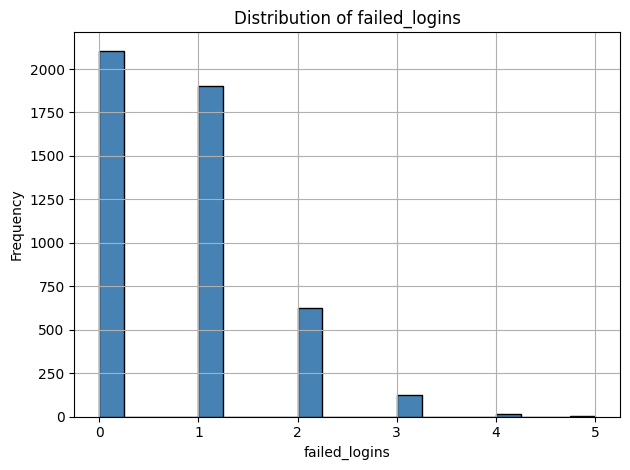

In [ ]:
df_clean['failed_logins'].hist(bins=20, color='steelblue', edgecolor='black')
plt.title('Distribution of failed_logins')
plt.xlabel('failed_logins')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

failed_logins is skewed, missing values will be imputed with the median

In [ ]:
df_clean['failed_logins'] = df_clean['failed_logins'].fillna(df_clean['failed_logins'].median())

In [ ]:
missing = df_clean.isnull().sum()
print(missing[missing > 0])

Series([], dtype: int64)


In [ ]:
df_clean.isnull().sum().sum()

np.int64(0)

In [ ]:
df_clean.shape

(5856, 19)

In [ ]:
outlier_cols = [c for c in df_clean.select_dtypes(include='number').columns
                if c != 'avg_packet_size']

keeping avg_packet_size as its the prediction target. capping not removing as network traffic extreme values like very high bytes_sent or packet_rate are genuine

In [ ]:
print("Clipping outliers (IQR method):")
for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    df_clean[col] = df_clean[col].clip(lower, upper)
    print(f"{col}: {n_out} outliers clipped to [{lower:.2f}, {upper:.2f}]")

print(f"\nShape after outlier handling: {df_clean.shape}")

Clipping outliers (IQR method):
login_attempts: 17 outliers clipped to [-2.00, 6.00]
failed_logins: 140 outliers clipped to [-1.50, 2.50]
bytes_sent: 99 outliers clipped to [948.73, 9064.30]
bytes_received: 70 outliers clipped to [1079.64, 11031.62]
packet_rate: 97 outliers clipped to [37.94, 201.76]
connection_count: 80 outliers clipped to [-1.50, 10.50]
port_number: 1265 outliers clipped to [-152.00, 320.00]
session_retries: 375 outliers clipped to [-1.50, 2.50]
signal_strength: 76 outliers clipped to [-84.37, -35.77]
anomaly_score: 31 outliers clipped to [-0.18, 0.74]

Shape after outlier handling: (5856, 19)


In [ ]:
print("Variance of numeric columns:")
print(df_clean.var(numeric_only=True).sort_values())

zero_var = df_clean.var(numeric_only=True)
cols_zero = zero_var[zero_var == 0].index
if len(cols_zero) > 0:
    df_clean.drop(columns=cols_zero, inplace=True)
    print(f"\nDropped zero-variance columns: {list(cols_zero)}")
else:
    print("\nNo zero-variance columns found.")

df_clean.drop(columns=['packet_session_id'], inplace=True)
print("Dropped 'packet_session_id' (unique identifier, no predictive value).")

print("\nNear-constant column check (top value > 95% of rows):")
for col in df_clean.columns:
    top_freq = df_clean[col].value_counts(normalize=True).iloc[0]
    if top_freq > 0.95:
        print(f"  {col} is near-constant ({top_freq:.1%}) -- consider dropping")
    else:
        print(f"  {col}: ok ({top_freq:.1%})")

print(f"\nShape after removing useless attributes: {df_clean.shape}")

Variance of numeric columns:
anomaly_score       2.585761e-02
failed_logins       4.736134e-01
session_retries     6.994351e-01
login_attempts      1.931379e+00
connection_count    4.532242e+00
signal_strength     8.990183e+01
avg_packet_size     5.418396e+02
packet_rate         9.282891e+02
port_number         1.248509e+04
bytes_sent          2.389355e+06
bytes_received      3.729829e+06
dtype: float64

No zero-variance columns found.
Dropped 'packet_session_id' (unique identifier, no predictive value).

Near-constant column check (top value > 95% of rows):
  protocol: ok (57.2%)
  device_type: ok (25.7%)
  vpn_status: ok (69.8%)
  region: ok (25.3%)
  login_attempts: ok (28.6%)
  failed_logins: ok (50.9%)
  bytes_sent: ok (1.4%)
  bytes_received: ok (6.9%)
  packet_rate: ok (1.4%)
  connection_count: ok (17.6%)
  tcp_flags: ok (25.5%)
  port_number: ok (21.6%)
  session_retries: ok (38.0%)
  signal_strength: ok (7.0%)
  privilege_level: ok (71.2%)
  anomaly_score: ok (0.5%)
  avg_pac

In [ ]:
df_clean['login_failure_rate'] = df_clean['failed_logins'] / (df_clean['login_attempts'] + 1)
df_clean['bytes_ratio'] = df_clean['bytes_sent'] / (df_clean['bytes_received'] + 1)
df_clean['retry_rate'] = df_clean['session_retries'] / (df_clean['connection_count'] + 1)

In [ ]:
print("new features constructed:")
print(df_clean[['login_failure_rate', 'bytes_ratio', 'retry_rate']].describe().round(3))
print(f"\nShape with new features: {df_clean.shape}")

new features constructed:
       login_failure_rate  bytes_ratio  retry_rate
count            5856.000     5856.000    5856.000
mean                0.312        0.968       0.164
std                 0.300        0.624       0.168
min                 0.000        0.086       0.000
25%                 0.000        0.619       0.000
50%                 0.333        0.828       0.143
75%                 0.500        1.132       0.250
max                 1.000        7.442       0.667

Shape with new features: (5856, 21)


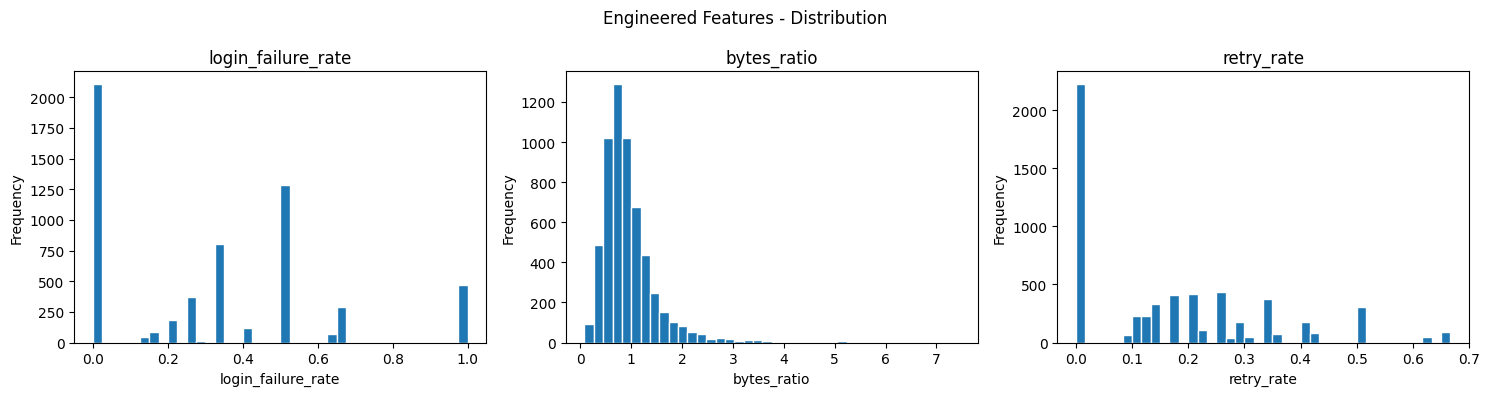

In [ ]:
# Visualise the new features
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
new_feats = ['login_failure_rate', 'bytes_ratio', 'retry_rate']
for ax, feat in zip(axes, new_feats):
    ax.hist(df_clean[feat], bins=40, edgecolor='white')
    ax.set_title(feat)
    ax.set_xlabel(feat)
    ax.set_ylabel('Frequency')
plt.suptitle('Engineered Features - Distribution')
plt.tight_layout()
plt.show()

In [ ]:
df_encoded = df_clean.copy()
label_encoders = {}

In [ ]:
feature_cat_cols = [c for c in df_encoded.select_dtypes(include='object').columns
                    if c != 'attack_category']

In [ ]:
for col in feature_cat_cols:
  le = LabelEncoder()
  df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
  label_encoders[col] = le
  print(f"{col}: {list(le.classes_)}")

protocol: ['icmp', 'tcp', 'udp']
device_type: ['iot', 'mobile', 'server', 'workstation']
vpn_status: ['off', 'on']
region: ['apac', 'eu', 'me', 'us']
tcp_flags: ['ack', 'fin', 'syn', 'syn-ack']
privilege_level: ['admin', 'guest', 'user']


Encoding the classification target separately so we can decode predictions later

In [ ]:
le_target = LabelEncoder()
df_encoded['attack_category_encoded'] = le_target.fit_transform(
    df_encoded['attack_category'].astype(str))

In [ ]:
feature_cols = [c for c in df_encoded.columns
                if c not in ['attack_category', 'attack_category_encoded', 'avg_packet_size']]

In [ ]:
print(f"Feature columns ({len(feature_cols)}):")
for col in feature_cols:
    print(f"  {col}")

Feature columns (19):
  protocol
  device_type
  vpn_status
  region
  login_attempts
  failed_logins
  bytes_sent
  bytes_received
  packet_rate
  connection_count
  tcp_flags
  port_number
  session_retries
  signal_strength
  privilege_level
  anomaly_score
  login_failure_rate
  bytes_ratio
  retry_rate


In [ ]:
X_class = df_encoded[feature_cols]
y_class = df_encoded['attack_category_encoded']

In [ ]:
X_pred = df_encoded[feature_cols]
y_pred = df_encoded['avg_packet_size']

In [ ]:
X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class, y_class, test_size=0.2, random_state=42, stratify=y_class)
X_pred_train, X_pred_test, y_pred_train, y_pred_test = train_test_split(
    X_pred, y_pred, test_size=0.2, random_state=42)

In [ ]:
print(f"\nClassification split -- Train: {X_class_train.shape[0]} | Test: {X_class_test.shape[0]}")
print(f"Prediction split -- Train: {X_pred_train.shape[0]} | Test: {X_pred_test.shape[0]}")


Classification split -- Train: 4684 | Test: 1172
Prediction split -- Train: 4684 | Test: 1172


In [ ]:
numeric_class_cols = X_class_train.select_dtypes(include='number').columns
numeric_pred_cols = X_pred_train.select_dtypes(include='number').columns

In [ ]:
scaler_class = MinMaxScaler()
X_class_train[numeric_class_cols] = scaler_class.fit_transform(X_class_train[numeric_class_cols])
X_class_test[numeric_class_cols]  = scaler_class.transform(X_class_test[numeric_class_cols])

In [ ]:
scaler_pred = MinMaxScaler()
X_pred_train[numeric_pred_cols] = scaler_pred.fit_transform(X_pred_train[numeric_pred_cols])
X_pred_test[numeric_pred_cols]  = scaler_pred.transform(X_pred_test[numeric_pred_cols])

In [ ]:
print(X_class_train[numeric_class_cols].describe().loc[['min','max']])

     protocol  device_type  vpn_status  region  login_attempts  failed_logins  \
min       0.0          0.0         0.0     0.0             0.0            0.0   
max       1.0          1.0         1.0     1.0             1.0            1.0   

     bytes_sent  bytes_received  packet_rate  connection_count  tcp_flags  \
min         0.0             0.0          0.0               0.0        0.0   
max         1.0             1.0          1.0               1.0        1.0   

     port_number  session_retries  signal_strength  privilege_level  \
min          0.0              0.0              0.0              0.0   
max          1.0              1.0              1.0              1.0   

     anomaly_score  login_failure_rate  bytes_ratio  retry_rate  
min            0.0                 0.0          0.0         0.0  
max            1.0                 1.0          1.0         1.0  


Classification Models:
| Algorithm | Decision | Reason |
|--------|-------------|-------------|
| `Decision Tree` | Use | Can handle this Dataset's mixed numeric and categorical features. Produces easy to understand interpretable if-then rules and feature importance scores |
| `Naive Bayes` | Not use | Better suited for Datasets with independent and mostly categorical features, and this Dataset is mostly numerical and has features that correlate with each other |
| `KNN` | Use | Provides a simple baseline for a medium, non-linear Dataset like this one |
| `Logistic Regression` | Not Use | It assumes a linear boundary between classes which is not this Dataset's case as seen by the scatter plot |
| `Linear Regression` | Not Use | It predicts a continuous number and not a class label |

---

## 5. Classification Model 1: Decision Tree (Baseline)

In [ ]:
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_class_train, y_class_train)

DecisionTreeClassifier(max_depth=5, random_state=42)

In [ ]:
y_pred_dt = dt_model.predict(X_class_test)
y_train_pred_dt = dt_model.predict(X_class_train)

In [ ]:
print(f"Train Accuracy: {accuracy_score(y_class_train, y_train_pred_dt):.4f}")
print(f"Test Accuracy: {accuracy_score(y_class_test, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_class_test, y_pred_dt, average='weighted', zero_division=0):.4f}")
print(f"Recall: {recall_score(y_class_test, y_pred_dt, average='weighted', zero_division=0):.4f}")
print(f"F1-Score: {f1_score(y_class_test, y_pred_dt, average='weighted', zero_division=0):.4f}")

Train Accuracy: 0.7047
Test Accuracy: 0.6860
Precision: 0.5808
Recall: 0.6860
F1-Score: 0.5782


In [ ]:
print(classification_report(y_class_test, y_pred_dt, target_names=le_target.classes_, zero_division=0))

              precision    recall  f1-score   support

      benign       0.69      0.98      0.81       814
  bruteforce       0.32      0.03      0.05       358

    accuracy                           0.69      1172
   macro avg       0.51      0.50      0.43      1172
weighted avg       0.58      0.69      0.58      1172



In [ ]:
cv_dt = cross_val_score(dt_model, X_class_train, y_class_train, cv=5, scoring='f1_weighted') #check how well it performs on unseen data to prevent overfitting
print(f"Cross-Validation F1 (5-fold): {cv_dt.mean():.4f} +/- {cv_dt.std():.4f}")

Cross-Validation F1 (5-fold): 0.5752 +/- 0.0040


In [ ]:
cm_dt = confusion_matrix(y_class_test, y_pred_dt)

In [ ]:
class_names = le_target.classes_

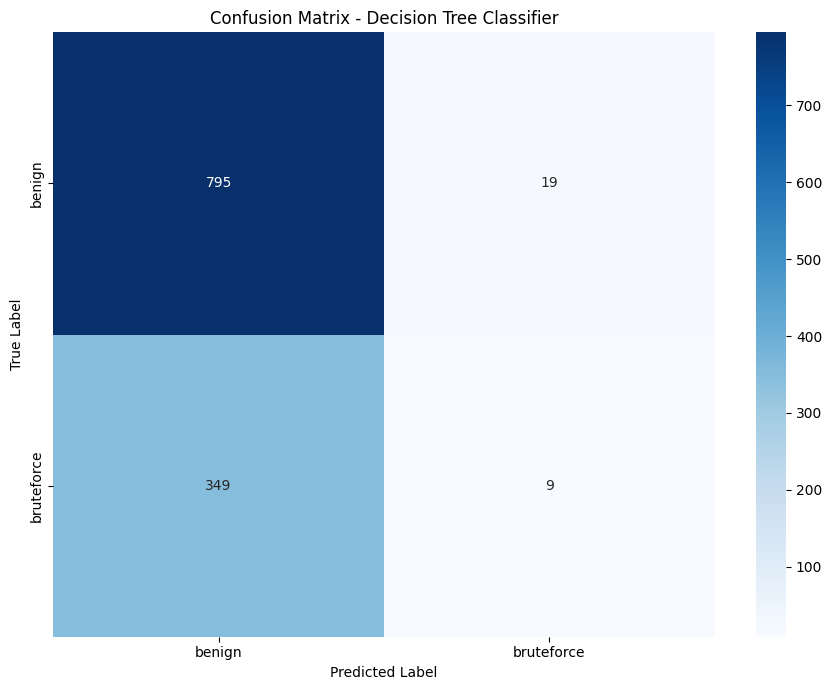

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - Decision Tree Classifier')
plt.tight_layout()
plt.show()

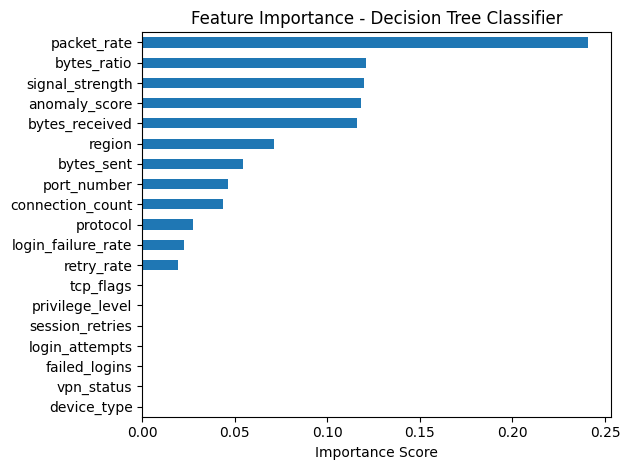

In [ ]:
importances = dt_model.feature_importances_
pd.Series(importances, index=feature_cols).sort_values().plot(kind='barh')
plt.title('Feature Importance - Decision Tree Classifier')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

## 6. Classification Model 2: KNN

In [ ]:
k_values = [3, 5, 7, 9, 11]
k_accuracies = []

print("Testing K values:")
for k in k_values:
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(X_class_train, y_class_train)
  y_pred_k = knn.predict(X_class_test)
  acc = accuracy_score(y_class_test, y_pred_k)
  k_accuracies.append(acc)
  print(f"  K={k}: {acc:.4f}")

Testing K values:
  K=3: 0.6246
  K=5: 0.6433
  K=7: 0.6544
  K=9: 0.6604
  K=11: 0.6672


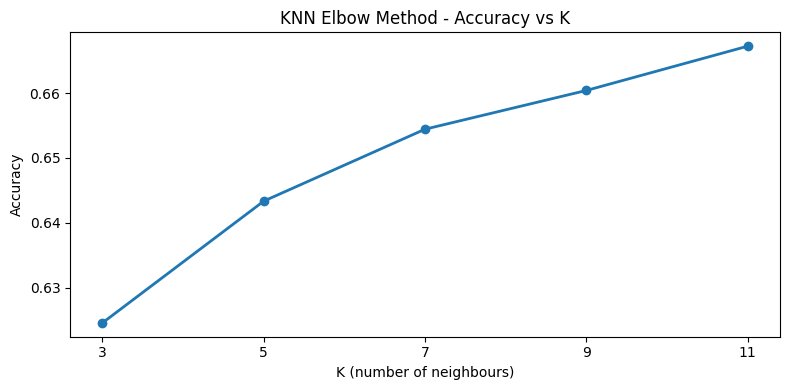

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(k_values, k_accuracies, marker='o', linewidth=2)
plt.xlabel('K (number of neighbours)')
plt.ylabel('Accuracy')
plt.title('KNN Elbow Method - Accuracy vs K')
plt.xticks(k_values)
plt.tight_layout()
plt.show()

In [ ]:
best_k = k_values[k_accuracies.index(max(k_accuracies))]
print(f"Best K = {best_k}  (accuracy: {max(k_accuracies):.4f})")

Best K = 11  (accuracy: 0.6672)


In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=best_k)
knn_model.fit(X_class_train, y_class_train)

KNeighborsClassifier(n_neighbors=11)

In [ ]:
y_pred_knn = knn_model.predict(X_class_test)
y_train_pred_knn = knn_model.predict(X_class_train)

In [ ]:
print(f"Train Accuracy: {accuracy_score(y_class_train, y_train_pred_knn):.4f}")
print(f"Test Accuracy: {accuracy_score(y_class_test, y_pred_knn):.4f}")
print(f"Precision: {precision_score(y_class_test, y_pred_knn, average='weighted', zero_division=0):.4f}")
print(f"Recall: {recall_score(y_class_test, y_pred_knn, average='weighted', zero_division=0):.4f}")
print(f"F1-Score: {f1_score(y_class_test, y_pred_knn, average='weighted', zero_division=0):.4f}")

Train Accuracy: 0.6992
Test Accuracy: 0.6672
Precision: 0.5832
Recall: 0.6672
F1-Score: 0.5923


In [ ]:
print(classification_report(y_class_test, y_pred_knn, target_names=le_target.classes_, zero_division=0))

              precision    recall  f1-score   support

      benign       0.70      0.92      0.79       814
  bruteforce       0.33      0.08      0.13       358

    accuracy                           0.67      1172
   macro avg       0.51      0.50      0.46      1172
weighted avg       0.58      0.67      0.59      1172



In [ ]:
cv_knn = cross_val_score(knn_model, scaler_class.transform(X_class), y_class, cv=5, scoring='f1_weighted')
print(f"Cross-Validation F1 (5-fold): {cv_knn.mean():.4f} +/- {cv_knn.std():.4f}")

Cross-Validation F1 (5-fold): 0.5905 +/- 0.0080


In [ ]:
cm_knn = confusion_matrix(y_class_test, y_pred_knn)

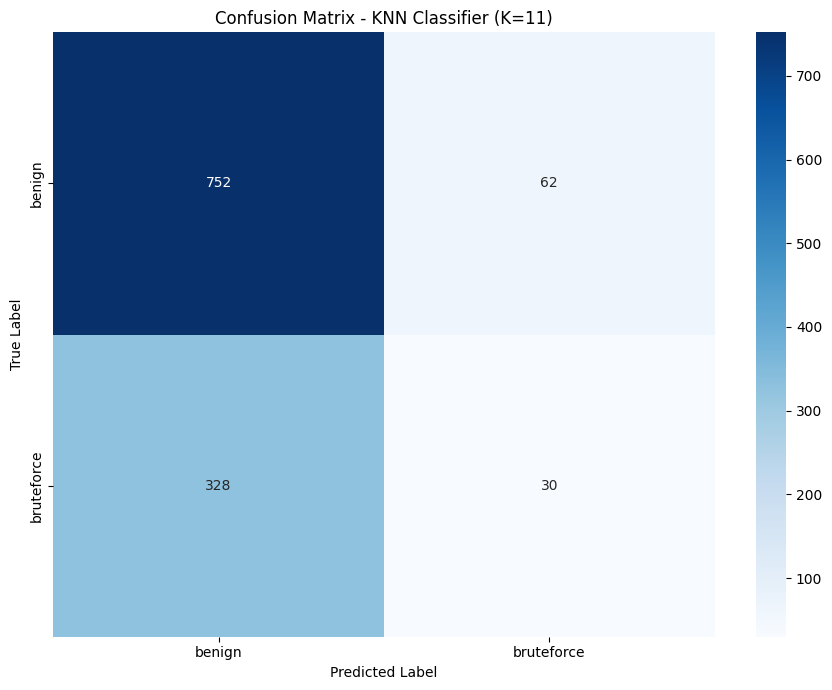

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix - KNN Classifier (K={best_k})')
plt.tight_layout()
plt.show()

## 7. Classification Model Comparison

In [ ]:
metrics_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
dt_scores = [accuracy_score(y_class_test, y_pred_dt),
             precision_score(y_class_test, y_pred_dt, average='weighted', zero_division=0),
             recall_score(y_class_test, y_pred_dt, average='weighted', zero_division=0),
             f1_score(y_class_test, y_pred_dt, average='weighted', zero_division=0)]
knn_scores = [accuracy_score(y_class_test, y_pred_knn),
              precision_score(y_class_test, y_pred_knn, average='weighted', zero_division=0),
              recall_score(y_class_test, y_pred_knn, average='weighted', zero_division=0),
              f1_score(y_class_test, y_pred_knn, average='weighted', zero_division=0)]

In [ ]:
print(f"{'Metric':<12} {'Decision Tree':>15} {f'KNN (K={best_k})':>12}")
print("-" * 42)
for metric, dv, kv in zip(metrics_labels, dt_scores, knn_scores):
    print(f"{metric:<12} {dv:>15.4f} {kv:>12.4f}")

Metric         Decision Tree   KNN (K=11)
------------------------------------------
Accuracy              0.6860       0.6672
Precision             0.5808       0.5832
Recall                0.6860       0.6672
F1-Score              0.5782       0.5923


Decision Tree wins on Accuracy (better at classifying overall) and Recall(catches more actual BruteForce sessions and misses fewer attacks)
KNN marginally wins on Precision (better at guessing Bruteforce sessions and has less false alarms) and F1-Score (balance between precision and recall). Given that a false negative (missed attack) is more harmful than a false positive (false alarm), Decision Tree would be better suited to the business' cybersecurity for having better recall

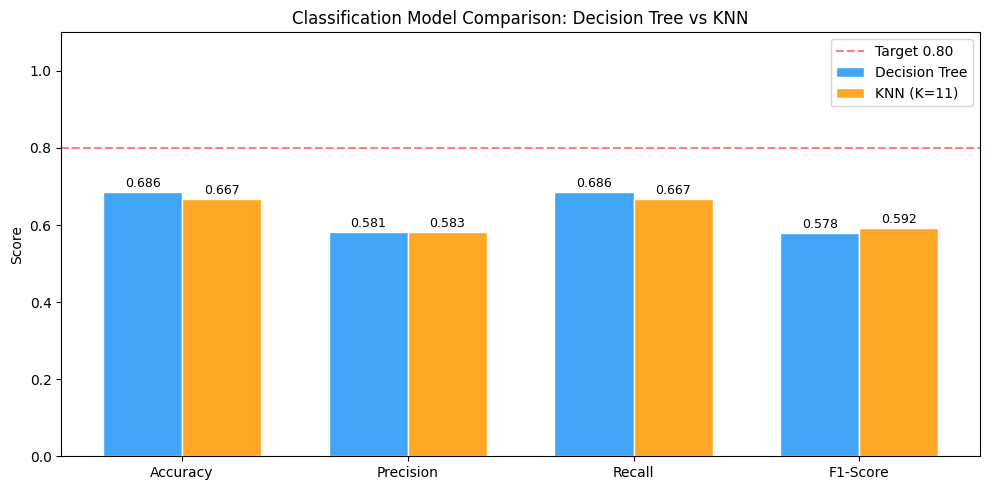

In [ ]:
x = np.arange(len(metrics_labels))
width = 0.35
fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, dt_scores, width, label='Decision Tree', color='#42A5F5', edgecolor='white')
bars2 = ax.bar(x + width/2, knn_scores, width, label=f'KNN (K={best_k})', color='#FFA726', edgecolor='white')
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Score')
ax.set_title('Classification Model Comparison: Decision Tree vs KNN')
ax.set_xticks(x); ax.set_xticklabels(metrics_labels)
ax.set_ylim(0, 1.1)
ax.axhline(0.8, color='red', linestyle='--', alpha=0.5, label='Target 0.80')
ax.legend()
plt.tight_layout()
plt.show()

Regression Models:
| Algorithm | Decision | Reason |
|--------|-------------|-------------|
| `Decision Tree Classification` | Not use | Predicts a class label and not a continuous number |
| `Decision Tree Regression` | Use | Can captures non-linear relationships |
| `Naive Bayes` | Not use | Designed for classification only and cannot predict a continuous numeric target |
| `KNN` | Not use | Provides no feature importance or coefficients to interpret the relationship between features and packet size |
| `Logistic Regression` | Not Use | Designed for classification only and cannot predict a continuous numeric target |
| `Linear Regression` | Use | Assumes a linear relationship between features and avg_packet_size |

---

## 8. Regression Model 1: Linear Regression (Baseline)

In [ ]:
lr_model = LinearRegression()
lr_model.fit(X_pred_train, y_pred_train)
y_pred_lr = lr_model.predict(X_pred_test)

In [ ]:
mse_lr = mean_squared_error(y_pred_test, y_pred_lr) #average of the squared differences between predicted and actual values
rmse_lr = np.sqrt(mse_lr) #brings the error back to the same unit as the target variable (bytes). More senstive to outliers
mae_lr = mean_absolute_error(y_pred_test, y_pred_lr) #average of the absolute differences between predicted and actual values
r2_lr = r2_score(y_pred_test, y_pred_lr) #how much of the variation is explained by the model on a scale from 0 to 1

In [ ]:
print("REGRESSION MODEL 1: Linear Regression (baseline)")
print(f"Root Mean Squared Error: {rmse_lr:.4f}")
print(f"Mean Absolute Error: {mae_lr:.4f}")
print(f"R2 (Coefficient of Determination): {r2_lr:.4f}")

REGRESSION MODEL 1: Linear Regression (baseline)
Root Mean Squared Error: 15.7830
Mean Absolute Error: 12.2665
R2 (Coefficient of Determination): 0.5480


## 9. Regression Model 2: Decision Tree Regressor (Improved)

In [ ]:
print("Testing max_depth values:")
for depth in [3, 5, 7, 10]:
  dtr = DecisionTreeRegressor(max_depth=depth, random_state=42)
  dtr.fit(X_pred_train, y_pred_train)
  y_pred_d = dtr.predict(X_pred_test)
  r2 = r2_score(y_pred_test, y_pred_d)
  rmse = np.sqrt(mean_squared_error(y_pred_test, y_pred_d))
  print(f"max_depth={depth}  ->  R2: {r2:.4f} | RMSE: {rmse:.4f}")

Testing max_depth values:
max_depth=3  ->  R2: 0.4293 | RMSE: 17.7338
max_depth=5  ->  R2: 0.4637 | RMSE: 17.1917
max_depth=7  ->  R2: 0.4408 | RMSE: 17.5545
max_depth=10  ->  R2: 0.2872 | RMSE: 19.8196


In [ ]:
best_depth = 5
dtr_model = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
dtr_model.fit(X_pred_train, y_pred_train)
y_pred_dtr = dtr_model.predict(X_pred_test)

In [ ]:
mse_dtr = mean_squared_error(y_pred_test, y_pred_dtr) #average of the squared differences between predicted and actual values
rmse_dtr = np.sqrt(mse_dtr) #brings the error back to the same unit as the target variable (bytes). More senstive to outliers
mae_dtr = mean_absolute_error(y_pred_test, y_pred_dtr) #average of the absolute differences between predicted and actual values
r2_dtr = r2_score(y_pred_test, y_pred_dtr) #how much of the variation is explained by the model on a scale from 0 to 1

In [ ]:
print(f"REGRESSION MODEL 2: Decision Tree Regressor (max_depth={best_depth})")
print(f"Root Mean Squared Error: {rmse_dtr:.4f}")
print(f"Mean Absolute Error: {mae_dtr:.4f}")
print(f"R2 (Coefficient of Determination): {r2_dtr:.4f}")

REGRESSION MODEL 2: Decision Tree Regressor (max_depth=5)
Root Mean Squared Error: 17.1917
Mean Absolute Error: 13.5788
R2 (Coefficient of Determination): 0.4637


## 10. Regression: Actual vs Predicted and Model Comparison

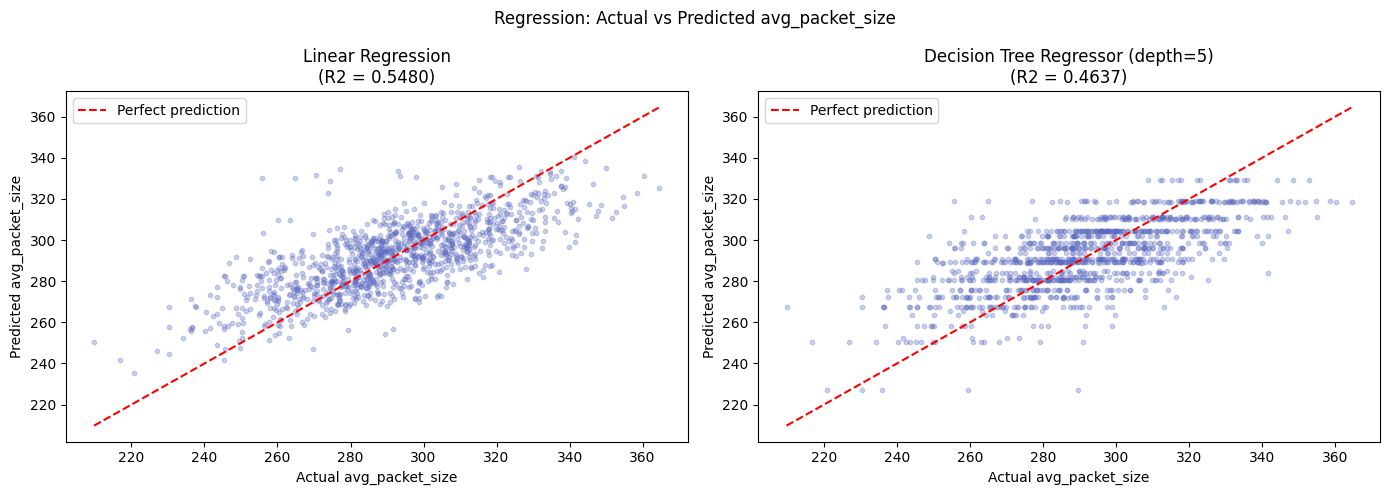

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, y_pred, title, r2 in zip(
    axes,
    [y_pred_lr, y_pred_dtr],
    ['Linear Regression', f'Decision Tree Regressor (depth={best_depth})'],
    [r2_lr, r2_dtr]
):
    ax.scatter(y_pred_test, y_pred, alpha=0.3, s=10, color='#5C6BC0')
    mn = min(y_pred_test.min(), y_pred.min())
    mx = max(y_pred_test.max(), y_pred.max())
    ax.plot([mn, mx], [mn, mx], 'r--', linewidth=1.5, label='Perfect prediction')
    ax.set_xlabel('Actual avg_packet_size')
    ax.set_ylabel('Predicted avg_packet_size')
    ax.set_title(f'{title}\n(R2 = {r2:.4f})')
    ax.legend()
plt.suptitle('Regression: Actual vs Predicted avg_packet_size')
plt.tight_layout()
plt.show()

Model                                        RMSE      MAE       R2
------------------------------------------------------------------
Linear Regression                         15.7830  12.2665   0.5480
Decision Tree Regressor                   17.1917  13.5788   0.4637


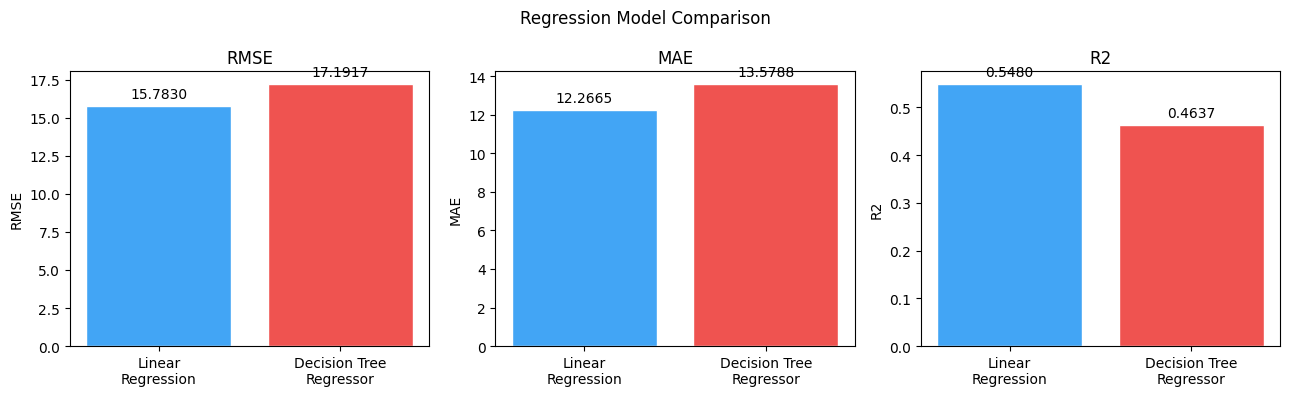

In [ ]:
print(f"{'Model':<40} {'RMSE':>8} {'MAE':>8} {'R2':>8}")
print("-" * 66)
print(f"{'Linear Regression':<40} {rmse_lr:>8.4f} {mae_lr:>8.4f} {r2_lr:>8.4f}")
print(f"{'Decision Tree Regressor':<40} {rmse_dtr:>8.4f} {mae_dtr:>8.4f} {r2_dtr:>8.4f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, metric, lv, rv in zip(axes, ['RMSE','MAE','R2'],
                               [rmse_lr, mae_lr, r2_lr],
                               [rmse_dtr, mae_dtr, r2_dtr]):
    bars = ax.bar(['Linear\nRegression','Decision Tree\nRegressor'],
                  [lv, rv], color=['#42A5F5','#EF5350'], edgecolor='white')
    for bar, val in zip(bars, [lv, rv]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.02,
                f'{val:.4f}', ha='center', va='bottom', fontsize=10)
    ax.set_title(metric); ax.set_ylabel(metric)
plt.suptitle('Regression Model Comparison')
plt.tight_layout()
plt.show()

Linear Regression is the better model here as it has the least averages of both the absolute and root of the squared differences between predicted and actual values compared to Decision Tree Regressor. It also can explain more of the data variation at 54.8% compared to the Decision Tree Regressor only explaining 46.37%. As shown in the scatter plots, avg_packet_size is closer to linear than non-linear which is why it performs better with Linear Regression which has a simpler structure that avoids overfitting to noise in the training data that the deeper Decision Tree picks up

## 11. Final Summary

In [ ]:
print("=" * 60)
print("FINAL SUMMARY")
print("=" * 60)

print("\n--- CLASSIFICATION TARGET (attack_category) ---")
print(f"Decision Tree (depth=5)  ->  Accuracy: {dt_scores[0]:.4f} | F1: {dt_scores[3]:.4f}")
print(f"KNN (K={best_k})  ->  Accuracy: {knn_scores[0]:.4f} | F1: {knn_scores[3]:.4f}")
best_class = "Decision Tree" if dt_scores[3] >= knn_scores[3] else f"KNN (K={best_k})"
print(f"Best Classifier: {best_class}")

print("\n--- PREDICTION TARGET (avg_packet_size) ---")
print(f"Linear Regression  ->  R2: {r2_lr:.4f} | RMSE: {rmse_lr:.4f}")
print(f"Decision Tree Regressor  ->  R2: {r2_dtr:.4f} | RMSE: {rmse_dtr:.4f}")
best_reg = "Linear Regression" if r2_lr >= r2_dtr else "Decision Tree Regressor"
print(f"Best Regressor: {best_reg}")

print("\n--- TOP FEATURES (Decision Tree Classifier) ---")
print(pd.Series(importances, index=feature_cols).sort_values(ascending=False).head())

FINAL SUMMARY

--- CLASSIFICATION TARGET (attack_category) ---
Decision Tree (depth=5)  ->  Accuracy: 0.6860 | F1: 0.5782
KNN (K=11)  ->  Accuracy: 0.6672 | F1: 0.5923
Best Classifier: KNN (K=11)

--- PREDICTION TARGET (avg_packet_size) ---
Linear Regression  ->  R2: 0.5480 | RMSE: 15.7830
Decision Tree Regressor  ->  R2: 0.4637 | RMSE: 17.1917
Best Regressor: Linear Regression

--- TOP FEATURES (Decision Tree Classifier) ---
packet_rate        0.241005
bytes_ratio        0.120856
signal_strength    0.119761
anomaly_score      0.117928
bytes_received     0.116174
dtype: float64


The Decision Tree classifier identifies attack type with interpretable rules the SOC team can audit directly. Key detection signals: anomaly_score, login_failure_rate, and bytes_sent. Sessions with anomaly_score > 0.8 and login_failure_rate > 0.7 should be auto-flagged for review